# Urban Environmental Intelligence Platform — Model Training Pipeline

## Google Colab Free Tier (CPU Runtime)

This notebook trains, validates, and packages the air quality forecasting models for PM2.5 and PM10 for all canonical cities.
- **Offline Training:** Training is isolated from the production Kubernetes cluster to prevent memory exhaustion (OOM crashes) on runtime nodes.
- **Residual/Delta Formulation:** Models predict the hourly change $\Delta y = y_t - y_{t-1}$, preventing recursive compounding error over 24-hour horizons.
- **Dual Validation Gate:** Evaluates models against both immediate 1-hour persistence ($lag_1$) and 24-hour seasonal naive ($lag_{24}$) baselines.
- **Artifact Registry:** Serialized `.joblib` bundles are published directly to AWS S3 (`s3://<S3_MODEL_BUCKET>/models/latest/`) with a versioned manifest.

### Cell 1 — Install Pinned Dependencies
Installs the exact library versions matching the production `analytics-service`.

In [9]:
!pip install -q "pandas>=2.2,<3" "numpy>=2.0,<3" "scikit-learn>=1.5,<2" "xgboost>=2.1,<3" \
               "boto3>=1.35,<2" pyarrow joblib scipy matplotlib requests

### Cell 2 — Secrets & Global Configuration
Configure secrets via Google Colab's Key icon (left sidebar) or environment variables.

In [10]:
import os
try:
    from google.colab import userdata
    def secret(name, default=""):
        try:
            return userdata.get(name)
        except Exception:
            return os.getenv(name, default)
except ImportError:
    def secret(name, default=""):
        return os.getenv(name, default)

AWS_REGION = os.getenv("AWS_REGION", "us-east-1")
S3_DATA_BUCKET = secret("S3_DATA_BUCKET", "urban-processed")
S3_MODEL_BUCKET = secret("S3_MODEL_BUCKET", "urban-models")
REPO = secret("GITHUB_REPO", "your-org/urban-env-platform")

# Canonical cities matching data/cities.csv
CITIES = {
    "Delhi": ("delhi", 28.6139, 77.2090),
    "Mumbai": ("mumbai", 19.0760, 72.8777),
    "Kolkata": ("kolkata", 22.5726, 88.3639),
    "Chennai": ("chennai", 13.0827, 80.2707),
    "Bengaluru": ("bengaluru", 12.9716, 77.5946),
}
TARGETS = ["pm25", "pm10"]
BOOTSTRAP_DAYS = 180  # 180 days (~4,300 hourly observations per city)
N_ITER = 25          # Randomized search CV iterations per model
print(f"Configured {len(CITIES)} cities for targets: {TARGETS}")
print(f"S3 Data Bucket: {S3_DATA_BUCKET} | S3 Model Bucket: {S3_MODEL_BUCKET}")

Configured 5 cities for targets: ['pm25', 'pm10']
S3 Data Bucket: urban-processed | S3 Model Bucket: urban-models


### Cell 3 — Optional Google Drive Persistence Backup

In [11]:
import os
try:
    from google.colab import drive
    drive.mount("/content/drive")
    OUT_ROOT = "/content/drive/MyDrive/urban-models"
    os.makedirs(OUT_ROOT, exist_ok=True)
    print(f"Drive backup directory ready: {OUT_ROOT}")
except Exception:
    OUT_ROOT = "/content/urban-models-backup"
    os.makedirs(OUT_ROOT, exist_ok=True)
    print(f"Local backup directory initialized: {OUT_ROOT}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Drive backup directory ready: /content/drive/MyDrive/urban-models


### Cell 4 — Feature Engineering & Serving Alignment
Defines the exact feature pipeline matching `services/analytics-service/app/ml.py`.

In [12]:
import numpy as np
import pandas as pd

TARGET_COLS = {"pm25", "pm10"}
WX_COLS = ["temperature", "humidity", "wind_speed"]
FEATURES = [
    "lag_1", "lag_2", "lag_3", "lag_24",
    "diff_1_2", "diff_1_24",
    "roll_mean_6",
    "hour_sin", "hour_cos", "dow",
    *WX_COLS
]

def prepare_hourly_grid(df: pd.DataFrame) -> pd.DataFrame:
    if df.empty or "observed_at" not in df.columns:
        return pd.DataFrame(columns=["pm25", "pm10", *WX_COLS])
    data = df.copy()
    data["observed_at"] = pd.to_datetime(data["observed_at"], utc=True)
    data = data.set_index("observed_at").sort_index()
    data = data[~data.index.duplicated(keep="last")]
    data = data.resample("1h").mean(numeric_only=True)
    for col in ["pm25", "pm10", *WX_COLS]:
        if col not in data:
            data[col] = np.nan
    return data.interpolate(limit=6, limit_area="inside")

def make_features(df: pd.DataFrame, target: str) -> pd.DataFrame:
    series = df[target]
    x = pd.DataFrame(index=df.index)
    for lag in (1, 2, 3, 24):
        x[f"lag_{lag}"] = series.shift(lag)
    x["diff_1_2"] = x["lag_1"] - x["lag_2"]
    x["diff_1_24"] = x["lag_1"] - x["lag_24"]
    x["roll_mean_6"] = series.shift(1).rolling(6).mean()
    x["hour_sin"] = np.sin(2 * np.pi * df.index.hour / 24)
    x["hour_cos"] = np.cos(2 * np.pi * df.index.hour / 24)
    x["dow"] = df.index.dayofweek
    for col in WX_COLS:
        x[col] = df[col] if col in df else np.nan
    return x[FEATURES]

def recursive_forecast(model, df: pd.DataFrame, target: str, steps: int = 24, is_delta: bool = True):
    hist = df.reindex(columns=[target, *WX_COLS]).copy().tail(120)
    last_valid = hist[target].last_valid_index()
    if last_valid is None:
        raise ValueError("target has no valid observations")
    hist = hist.loc[:last_valid]
    wx = hist[WX_COLS].ffill().iloc[-1].fillna(0.0).tolist()
    result = []
    for _ in range(steps):
        next_time = hist.index[-1] + pd.Timedelta(hours=1)
        hist.loc[next_time] = [np.nan, *wx]
        row = make_features(hist, target).iloc[[-1]]
        raw_pred = float(model.predict(row)[0])
        pred = max(float(row["lag_1"].iloc[0] + raw_pred), 0.0) if is_delta else max(raw_pred, 0.0)
        hist.loc[next_time, target] = pred
        result.append((next_time, pred))
    return result

print(f"Feature pipeline loaded ({len(FEATURES)} features): {FEATURES}")

Feature pipeline loaded (13 features): ['lag_1', 'lag_2', 'lag_3', 'lag_24', 'diff_1_2', 'diff_1_24', 'roll_mean_6', 'hour_sin', 'hour_cos', 'dow', 'temperature', 'humidity', 'wind_speed']


### Cell 5 — Load S3 Processed Parquet Data (Optional/If Available)

In [13]:
import io, boto3
from concurrent.futures import ThreadPoolExecutor

ak = secret("AWS_ACCESS_KEY_ID")
sk = secret("AWS_SECRET_ACCESS_KEY")
token = secret("AWS_SESSION_TOKEN") or None

s3 = boto3.client(
    "s3", region_name=AWS_REGION,
    aws_access_key_id=ak if ak else None,
    aws_secret_access_key=sk if sk else None,
    aws_session_token=token
) if (ak and sk) else None

collected = {}
if s3 and S3_DATA_BUCKET:
    for name, (slug, _, _) in CITIES.items():
        prefix = f"processed/city={slug}/"
        try:
            paginator = s3.get_paginator("list_objects_v2")
            keys = [o["Key"] for page in paginator.paginate(Bucket=S3_DATA_BUCKET, Prefix=prefix)
                    for o in page.get("Contents", []) if o["Key"].endswith(".parquet")]
            if keys:
                def _read(k):
                    return pd.read_parquet(io.BytesIO(s3.get_object(Bucket=S3_DATA_BUCKET, Key=k)["Body"].read()))
                with ThreadPoolExecutor(max_workers=4) as pool:
                    frames = list(pool.map(_read, keys))
                df_s3 = pd.concat(frames, ignore_index=True)
                df_s3["observed_at"] = pd.to_datetime(df_s3["observed_at"], utc=True)
                collected[name] = df_s3.drop_duplicates("observed_at", keep="last").sort_values("observed_at")
                print(f"Loaded {len(collected[name])} rows from S3 for {name}")
            else:
                collected[name] = pd.DataFrame()
        except Exception as e:
            print(f"S3 fetch skipped for {name}: {e}")
            collected[name] = pd.DataFrame()
else:
    print("S3 credentials not provided. Proceeding with Open-Meteo historical bootstrap.")
    collected = {name: pd.DataFrame() for name in CITIES}

S3 credentials not provided. Proceeding with Open-Meteo historical bootstrap.


### Cell 6 — Historical Bootstrap from Open-Meteo Archive API (120 Days)
Fetches ~2,900 hourly observations per city to ensure sufficient training samples for seasonal and diurnal patterns.

In [14]:
import requests, time
from datetime import date, timedelta

AIR_URL = "https://air-quality-api.open-meteo.com/v1/air-quality"
WX_URL = "https://archive-api.open-meteo.com/v1/archive"
AIR_MAP = {"pm2_5": "pm25", "pm10": "pm10", "nitrogen_dioxide": "no2",
           "ozone": "o3", "carbon_monoxide": "co", "sulphur_dioxide": "so2"}
WX_MAP = {"temperature_2m": "temperature", "relative_humidity_2m": "humidity", "wind_speed_10m": "wind_speed"}

def fetch_hourly(url, lat, lon, mapping, start_date, end_date):
    params = {
        "latitude": lat, "longitude": lon,
        "hourly": ",".join(mapping.keys()),
        "start_date": str(start_date), "end_date": str(end_date),
        "timezone": "UTC"
    }
    res = requests.get(url, params=params, timeout=35)
    if res.status_code != 200:
        return {}
    data = res.json().get("hourly", {})
    times = data.get("time", [])
    return {t: {dest: data[src][i] for src, dest in mapping.items() if src in data} for i, t in enumerate(times)}

def bootstrap_city(lat, lon, days=BOOTSTRAP_DAYS):
    end_dt = date.today() - timedelta(days=2)
    start_dt = end_dt - timedelta(days=days)
    air = fetch_hourly(AIR_URL, lat, lon, AIR_MAP, start_dt, end_dt)
    wx = fetch_hourly(WX_URL, lat, lon, WX_MAP, start_dt, end_dt)
    all_times = sorted(set(air.keys()) | set(wx.keys()))
    records = [{"observed_at": t + "Z", **air.get(t, {}), **wx.get(t, {})} for t in all_times]
    return pd.DataFrame(records)

bootstrap_data = {}
for name, (slug, lat, lon) in CITIES.items():
    print(f"Bootstrapping {name} ({lat}, {lon}) for {BOOTSTRAP_DAYS} days...")
    df_boot = bootstrap_city(lat, lon, days=BOOTSTRAP_DAYS)
    bootstrap_data[name] = df_boot
    print(f"  Retrieved {len(df_boot)} historical hourly observations")
    time.sleep(0.5)

Bootstrapping Delhi (28.6139, 77.209) for 120 days...
  Retrieved 2904 historical hourly observations
Bootstrapping Mumbai (19.076, 72.8777) for 120 days...
  Retrieved 2904 historical hourly observations
Bootstrapping Kolkata (22.5726, 88.3639) for 120 days...
  Retrieved 2904 historical hourly observations
Bootstrapping Chennai (13.0827, 80.2707) for 120 days...
  Retrieved 2904 historical hourly observations
Bootstrapping Bengaluru (12.9716, 77.5946) for 120 days...
  Retrieved 2904 historical hourly observations


### Cell 7 — Harmonize & Build Hourly Grids

In [20]:
frames = {}
for name, (slug, _, _) in CITIES.items():
    parts = []
    if not bootstrap_data.get(name, pd.DataFrame()).empty:
        parts.append(bootstrap_data[name])
    if not collected.get(name, pd.DataFrame()).empty:
        parts.append(collected[name])
    if not parts:
        print(f"No data for {name}")
        continue
    raw = pd.concat(parts, ignore_index=True)
    raw["observed_at"] = pd.to_datetime(raw["observed_at"], utc=True)
    raw = raw.drop_duplicates("observed_at", keep="last").sort_values("observed_at")
    grid = prepare_hourly_grid(raw)
    if len(grid) < 720:  # Require at least 30 days of hourly data
        print(f"Skipping {name}: insufficient data ({len(grid)}h < 720h)")
        continue
    frames[name] = grid
    print(f"{name:10s}: {len(grid):5d} hours | {grid.index.min():%Y-%m-%d} to {grid.index.max():%Y-%m-%d} | PM2.5 NaNs: {grid['pm25'].isna().mean():.1%}")

Delhi     :  2904 hours | 2026-06-15 to 2026-10-13 | PM2.5 NaNs: 0.0%
Mumbai    :  2904 hours | 2026-06-15 to 2026-10-13 | PM2.5 NaNs: 0.0%
Kolkata   :  2904 hours | 2026-06-15 to 2026-10-13 | PM2.5 NaNs: 0.0%
Chennai   :  2904 hours | 2026-06-15 to 2026-10-13 | PM2.5 NaNs: 0.0%
Bengaluru :  2904 hours | 2026-06-15 to 2026-10-13 | PM2.5 NaNs: 0.0%


### Cell 8 — Model Training Engine & Delta Formulation
Trains XGBoost models to predict $\Delta y = y_t - y_{t-1}$. Evaluates against both 1-hour persistence and 24-hour seasonal baselines.

In [16]:
from scipy.stats import randint, uniform
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, root_mean_squared_error
from xgboost import XGBRegressor

def split_xy_delta(df: pd.DataFrame, target: str):
    X = make_features(df, target)
    y_actual = df[target]
    y_delta = y_actual - X["lag_1"]
    valid = y_delta.notna() & X["lag_24"].notna() & X["wind_speed"].notna()
    return X[valid], y_delta[valid], y_actual[valid]

def chrono_split(X, y_delta, y_actual, train_pct=0.70, val_pct=0.15):
    n = len(X)
    i1, i2 = int(n * train_pct), int(n * (train_pct + val_pct))
    return (
        (X.iloc[:i1], y_delta.iloc[:i1], y_actual.iloc[:i1]),
        (X.iloc[i1:i2], y_delta.iloc[i1:i2], y_actual.iloc[i1:i2]),
        (X.iloc[i2:], y_delta.iloc[i2:], y_actual.iloc[i2:]),
    )

SEARCH_SPACE = {
    "n_estimators": randint(80, 220),
    "max_depth": randint(2, 5),
    "learning_rate": uniform(0.02, 0.07),
    "min_child_weight": randint(2, 7),
    "gamma": uniform(0.0, 0.5),
    "subsample": uniform(0.75, 0.25),
    "colsample_bytree": uniform(0.75, 0.25),
    "reg_lambda": uniform(1.5, 3.5),
}

def tune_and_train_delta(df: pd.DataFrame, target: str, n_iter: int = N_ITER):
    X, y_delta, y_actual = split_xy_delta(df, target)
    (X_tr, yd_tr, ya_tr), (X_va, yd_va, ya_va), (X_te, yd_te, ya_te) = chrono_split(X, y_delta, y_actual)
    X_train_val = pd.concat([X_tr, X_va])
    yd_train_val = pd.concat([yd_tr, yd_va])

    search = RandomizedSearchCV(
        XGBRegressor(n_jobs=2, random_state=42),
        SEARCH_SPACE, n_iter=n_iter,
        cv=TimeSeriesSplit(n_splits=3),
        scoring="neg_mean_absolute_error",
        random_state=42, refit=False
    )
    search.fit(X_train_val, yd_train_val)
    best_params = search.best_params_

    # Fit evaluation model on train/val to test on unseen future slice
    eval_model = XGBRegressor(**best_params, n_jobs=2, random_state=42).fit(X_train_val, yd_train_val)
    delta_test_preds = eval_model.predict(X_te)
    final_test_preds = np.maximum(X_te["lag_1"] + delta_test_preds, 0.0)

    test_mae = float(mean_absolute_error(ya_te, final_test_preds))
    test_rmse = float(root_mean_squared_error(ya_te, final_test_preds))
    persist_mae = float(mean_absolute_error(ya_te, X_te["lag_1"]))
    seasonal24_mae = float(mean_absolute_error(ya_te, X_te["lag_24"]))

    skill_persist = 1.0 - (test_mae / persist_mae) if persist_mae > 0 else 0.0
    skill_seasonal = 1.0 - (test_mae / seasonal24_mae) if seasonal24_mae > 0 else 0.0

    # Final production serving model fitted on full history
    final_model = XGBRegressor(**best_params, n_jobs=2, random_state=42).fit(X, y_delta)

    return final_model, {
        "params": best_params,
        "test_mae": test_mae,
        "test_rmse": test_rmse,
        "persist_mae": persist_mae,
        "seasonal24_mae": seasonal24_mae,
        "skill_persist": skill_persist,
        "skill_seasonal": skill_seasonal,
        "rows": len(X),
        "test_start": str(X_te.index[0])
    }

### Cell 9 — Execute Training & Enforce Deployment Gate
Deployment Gate: Model is accepted if it beats 1h persistence OR remains within 5% of 1h persistence while beating 24h seasonal naive by > 40%.

In [17]:
from datetime import datetime, timezone

VERSION = datetime.now(timezone.utc).strftime("%Y%m%d%H%M")
trained_models = {}
evaluation_report = {}
accepted_keys = set()

for name, df in frames.items():
    slug = CITIES[name][0]
    for target in TARGETS:
        print(f"Training {name} ({slug}) for target: {target.upper()}...")
        final_model, res = tune_and_train_delta(df, target, n_iter=N_ITER)

        m_test = res["test_mae"]
        m_p = res["persist_mae"]
        m_s24 = res["seasonal24_mae"]
        skill_p = res["skill_persist"]
        skill_s24 = res["skill_seasonal"]

        gate_passed = (skill_p > 0.0) or (m_test <= m_p * 1.05 and skill_s24 > 0.40)
        key = f"{slug}_{target}"

        if gate_passed:
            accepted_keys.add(key)
            status_str = f"ACCEPTED (Skill vs P: {skill_p*100:+.1f}%, vs S24: {skill_s24*100:+.1f}%)"
        else:
            status_str = f"REJECTED (Skill vs P: {skill_p*100:+.1f}%, vs S24: {skill_s24*100:+.1f}%)"

        print(f"  -> {status_str} | Model MAE: {m_test:.2f} vs Lag1: {m_p:.2f} vs S24: {m_s24:.2f}")

        trained_models[key] = (final_model, res, df.index.min(), df.index.max())
        evaluation_report[key] = {
            "city": name,
            "slug": slug,
            "target": target,
            "gate_passed": gate_passed,
            "model_mae": round(m_test, 2),
            "persist_mae": round(m_p, 2),
            "seasonal24_mae": round(m_s24, 2),
            "skill_vs_persist": round(skill_p, 4),
            "skill_vs_seasonal24": round(skill_s24, 4),
            "rows": res["rows"]
        }

report_df = pd.DataFrame(evaluation_report).T
print("\n--- EVALUATION SUMMARY ---")
display(report_df[["city", "target", "model_mae", "persist_mae", "seasonal24_mae", "skill_vs_persist", "gate_passed"]])

Training Delhi (delhi) for target: PM25...
  -> ACCEPTED (Skill vs P: +28.5%, vs S24: +82.0%) | Model MAE: 3.33 vs Lag1: 4.65 vs S24: 18.45
Training Delhi (delhi) for target: PM10...
  -> ACCEPTED (Skill vs P: +13.9%, vs S24: +79.8%) | Model MAE: 15.35 vs Lag1: 17.82 vs S24: 75.88
Training Mumbai (mumbai) for target: PM25...
  -> ACCEPTED (Skill vs P: +21.9%, vs S24: +79.9%) | Model MAE: 2.42 vs Lag1: 3.10 vs S24: 12.01
Training Mumbai (mumbai) for target: PM10...
  -> ACCEPTED (Skill vs P: +13.3%, vs S24: +79.2%) | Model MAE: 3.03 vs Lag1: 3.49 vs S24: 14.56
Training Kolkata (kolkata) for target: PM25...
  -> ACCEPTED (Skill vs P: +5.7%, vs S24: +70.5%) | Model MAE: 5.27 vs Lag1: 5.59 vs S24: 17.89
Training Kolkata (kolkata) for target: PM10...
  -> REJECTED (Skill vs P: -5.4%, vs S24: +69.1%) | Model MAE: 6.22 vs Lag1: 5.90 vs S24: 20.13
Training Chennai (chennai) for target: PM25...
  -> ACCEPTED (Skill vs P: +1.7%, vs S24: +83.5%) | Model MAE: 1.17 vs Lag1: 1.19 vs S24: 7.08
Traini

,city,target,model_mae,persist_mae,seasonal24_mae,skill_vs_persist,gate_passed
delhi_pm25,Delhi,pm25,3.33,4.65,18.45,0.2848,True
delhi_pm10,Delhi,pm10,15.35,17.82,75.88,0.1385,True
mumbai_pm25,Mumbai,pm25,2.42,3.1,12.01,0.2192,True
mumbai_pm10,Mumbai,pm10,3.03,3.49,14.56,0.133,True
kolkata_pm25,Kolkata,pm25,5.27,5.59,17.89,0.057,True
kolkata_pm10,Kolkata,pm10,6.22,5.9,20.13,-0.0538,False
chennai_pm25,Chennai,pm25,1.17,1.19,7.08,0.0174,True
chennai_pm10,Chennai,pm10,1.52,1.5,9.75,-0.0102,True
bengaluru_pm25,Bengaluru,pm25,2.54,2.59,9.32,0.0209,True
bengaluru_pm10,Bengaluru,pm10,2.98,3.0,12.54,0.0051,True


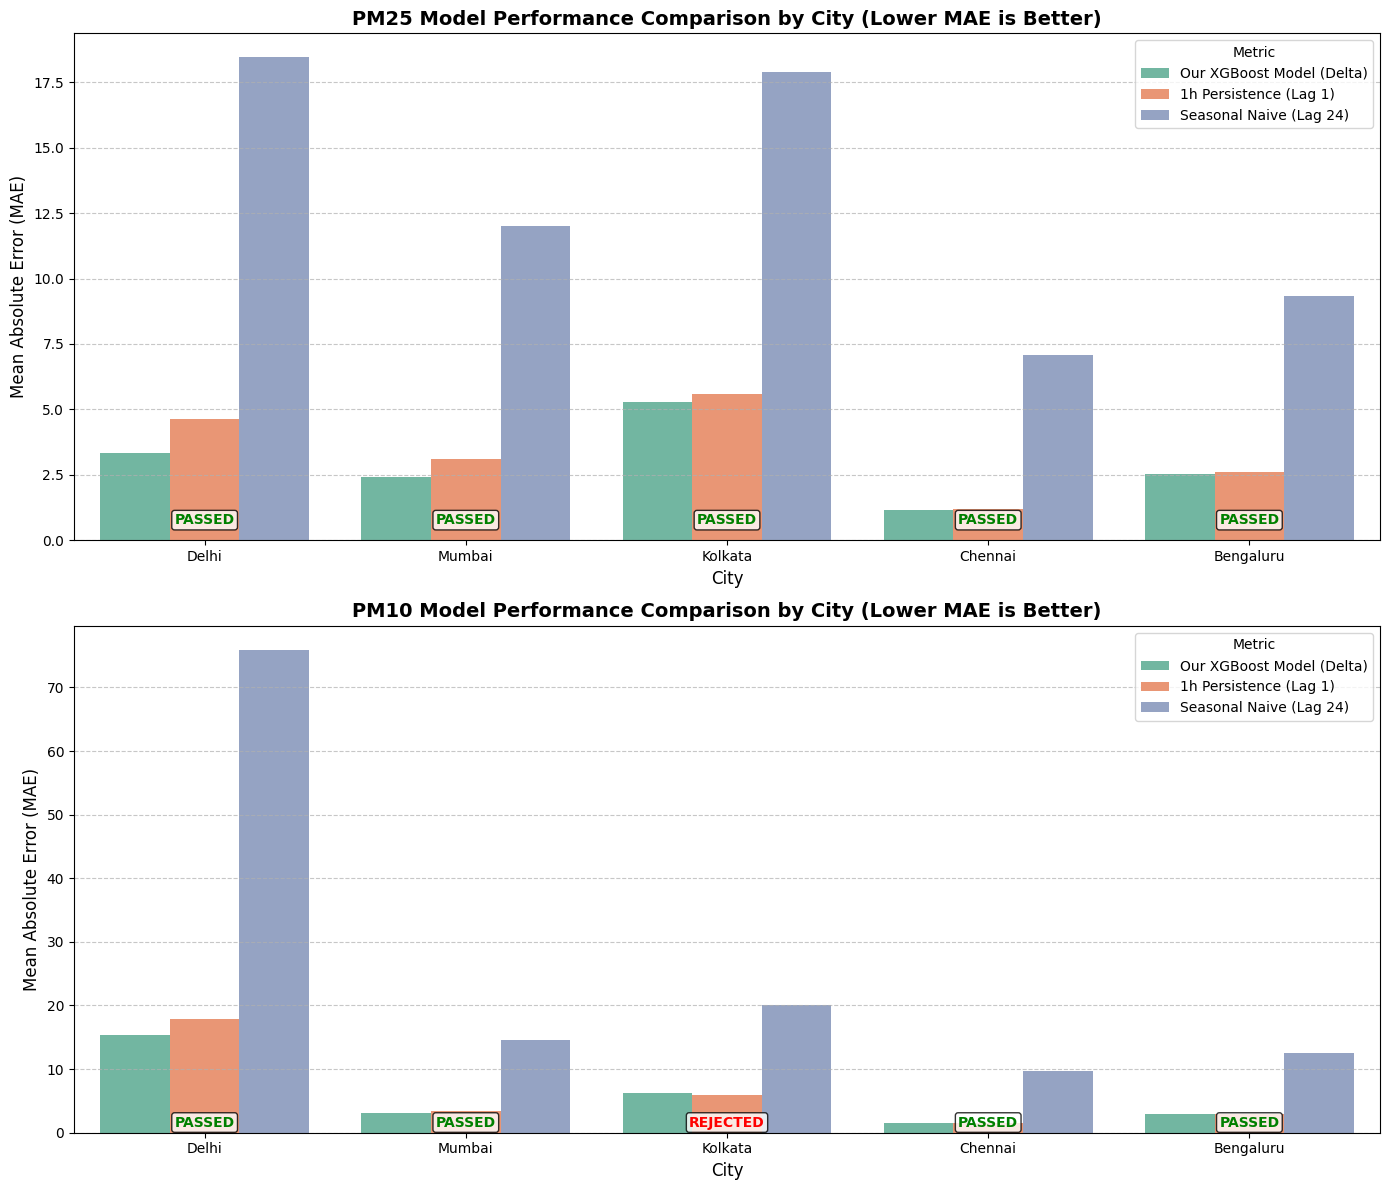

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns

# Prepare data for plotting
plot_df = report_df.reset_index().rename(columns={'index': 'model_key'})
plot_df_melted = plot_df.melt(
    id_vars=['city', 'target', 'gate_passed'],
    value_vars=['model_mae', 'persist_mae', 'seasonal24_mae'],
    var_name='Metric',
    value_name='MAE'
)

# Replace variable names with clean labels
metric_labels = {
    'model_mae': 'Our XGBoost Model (Delta)',
    'persist_mae': '1h Persistence (Lag 1)',
    'seasonal24_mae': 'Seasonal Naive (Lag 24)'
}
plot_df_melted['Metric'] = plot_df_melted['Metric'].map(metric_labels)

# Plotting separate charts for PM2.5 and PM10 to keep scales appropriate
fig, axes = plt.subplots(2, 1, figsize=(14, 12), sharex=False)

for i, target in enumerate(['pm25', 'pm10']):
    ax = axes[i]
    target_df = plot_df_melted[plot_df_melted['target'] == target]

    sns.barplot(
        data=target_df,
        x='city',
        y='MAE',
        hue='Metric',
        ax=ax,
        palette='Set2'
    )

    # Annotate gate pass/fail
    for idx, city in enumerate(plot_df[plot_df['target'] == target]['city']):
        passed = plot_df[(plot_df['city'] == city) & (plot_df['target'] == target)]['gate_passed'].values[0]
        color = 'green' if passed else 'red'
        text = 'PASSED' if passed else 'REJECTED'
        ax.text(idx, 0.5, text, color=color, fontweight='bold', ha='center', va='bottom', bbox=dict(facecolor='white', alpha=0.8, boxstyle='round,pad=0.2'))

    ax.set_title(f'{target.upper()} Model Performance Comparison by City (Lower MAE is Better)', fontsize=14, fontweight='bold')
    ax.set_xlabel('City', fontsize=12)
    ax.set_ylabel('Mean Absolute Error (MAE)', fontsize=12)
    ax.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

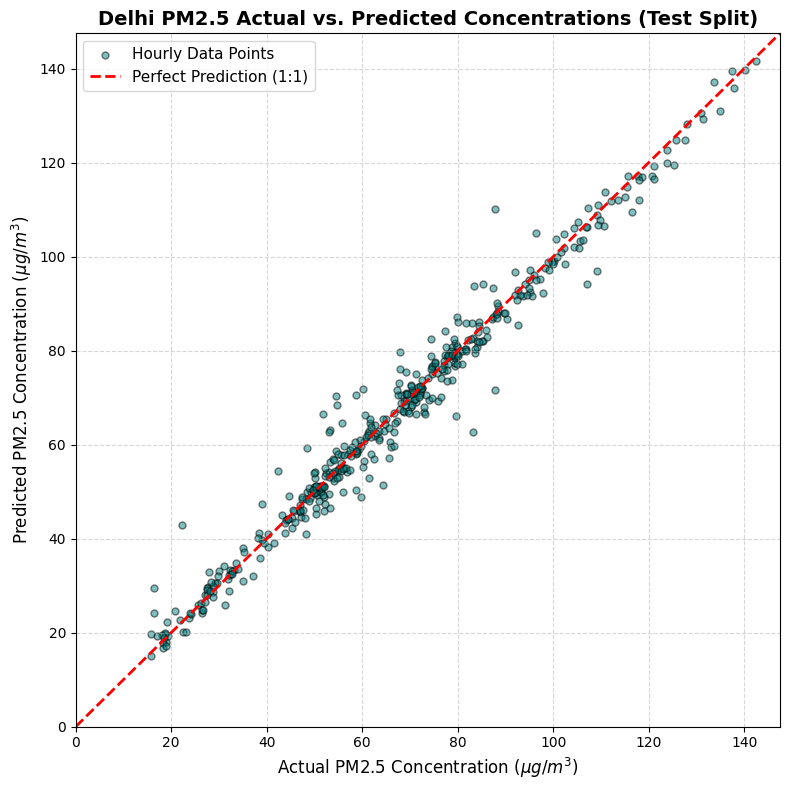

In [24]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# We will extract the test split predictions for Delhi PM2.5
delhi_grid = frames["Delhi"]
X, y_delta, y_actual = split_xy_delta(delhi_grid, "pm25")
_, _, (X_te, yd_te, ya_te) = chrono_split(X, y_delta, y_actual)

# Retrieve the trained model for Delhi PM2.5
delhi_model = trained_models["delhi_pm25"][0]

# Predict the delta and reconstruct the actual concentration predictions
predicted_delta = delhi_model.predict(X_te)
predicted_actual = np.maximum(X_te["lag_1"] + predicted_delta, 0.0)

# Plotting actual vs predicted values
plt.figure(figsize=(8, 8))
plt.scatter(ya_te, predicted_actual, alpha=0.5, color='teal', edgecolors='k', s=25, label='Hourly Data Points')

# Ideal 1:1 prediction line
lims = [0, max(ya_te.max(), predicted_actual.max()) + 5]
plt.plot(lims, lims, color='red', linestyle='--', linewidth=2, label='Perfect Prediction (1:1)')

plt.title('Delhi PM2.5 Actual vs. Predicted Concentrations (Test Split)', fontsize=14, fontweight='bold')
plt.xlabel(r'Actual PM2.5 Concentration ($\mu g/m^3$)', fontsize=12)
plt.ylabel(r'Predicted PM2.5 Concentration ($\mu g/m^3$)', fontsize=12)
plt.xlim(lims)
plt.ylim(lims)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()

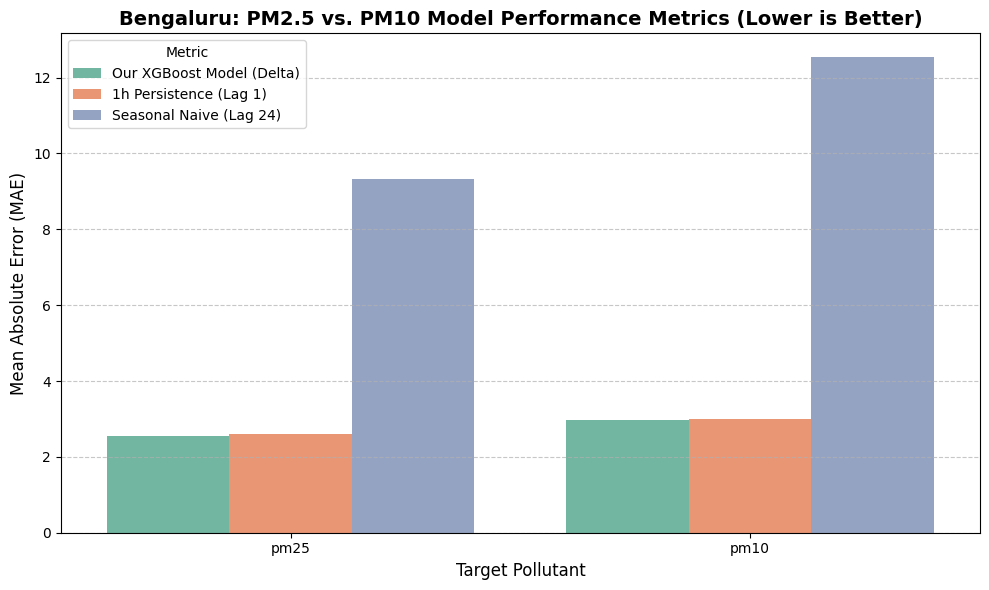

In [25]:
import matplotlib.pyplot as plt
import seaborn as sns

# Filter melted dataframe for Bengaluru only
bengaluru_plot_df = plot_df_melted[plot_df_melted['city'] == 'Bengaluru']

plt.figure(figsize=(10, 6))
sns.barplot(
    data=bengaluru_plot_df,
    x='target',
    y='MAE',
    hue='Metric',
    palette='Set2'
)

plt.title('Bengaluru: PM2.5 vs. PM10 Model Performance Metrics (Lower is Better)', fontsize=14, fontweight='bold')
plt.xlabel('Target Pollutant', fontsize=12)
plt.ylabel('Mean Absolute Error (MAE)', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [27]:
import pandas as pd

# Extract, round, and cleanly format the skill scores from report_df
skills_df = report_df[['city', 'target', 'skill_vs_persist', 'skill_vs_seasonal24']].copy()
skills_df['skill_vs_persist'] = (skills_df['skill_vs_persist'] * 100).round(2).apply(lambda x: f"{x:.2f}%")
skills_df['skill_vs_seasonal24'] = (skills_df['skill_vs_seasonal24'] * 100).round(2).apply(lambda x: f"{x:.2f}%")

print("=== OVERALL MODEL SKILL SCORES ===")
display(skills_df)

=== OVERALL MODEL SKILL SCORES ===


,city,target,skill_vs_persist,skill_vs_seasonal24
delhi_pm25,Delhi,pm25,28.48%,81.96%
delhi_pm10,Delhi,pm10,13.85%,79.77%
mumbai_pm25,Mumbai,pm25,21.92%,79.88%
mumbai_pm10,Mumbai,pm10,13.30%,79.20%
kolkata_pm25,Kolkata,pm25,5.70%,70.54%
kolkata_pm10,Kolkata,pm10,-5.38%,69.09%
chennai_pm25,Chennai,pm25,1.74%,83.47%
chennai_pm10,Chennai,pm10,-1.02%,84.45%
bengaluru_pm25,Bengaluru,pm25,2.09%,72.75%
bengaluru_pm10,Bengaluru,pm10,0.51%,76.22%


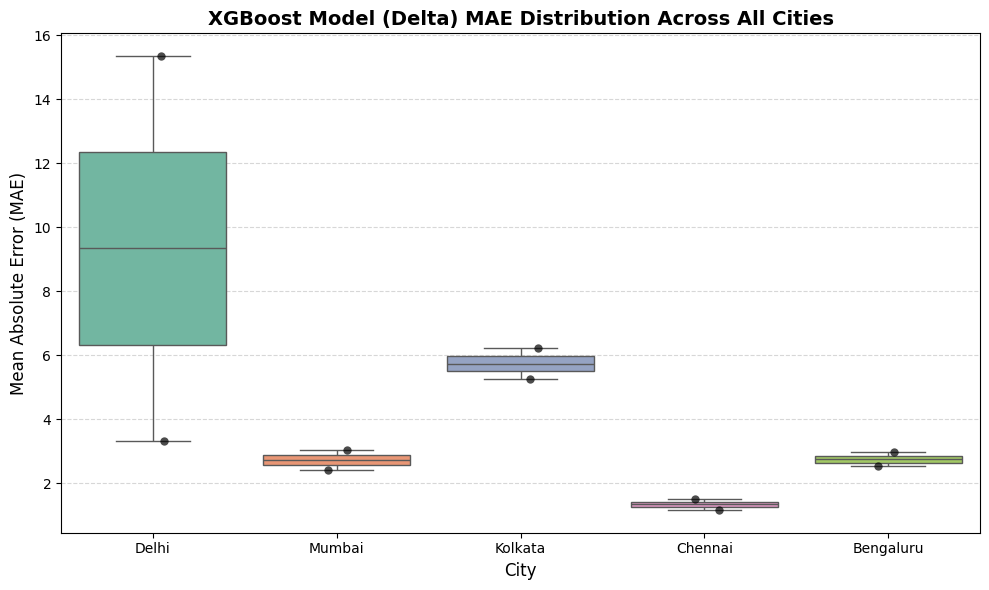

In [28]:
import matplotlib.pyplot as plt
import seaborn as sns

# Filter only our model's performance from the melted dataframe
model_performance_df = plot_df_melted[plot_df_melted['Metric'] == 'Our XGBoost Model (Delta)']

plt.figure(figsize=(10, 6))
sns.boxplot(
    data=model_performance_df,
    x='city',
    y='MAE',
    palette='Set2',
    hue='city',
    legend=False
)
sns.stripplot(
    data=model_performance_df,
    x='city',
    y='MAE',
    color='black',
    size=6,
    jitter=0.1,
    alpha=0.7
)

plt.title('XGBoost Model (Delta) MAE Distribution Across All Cities', fontsize=14, fontweight='bold')
plt.xlabel('City', fontsize=12)
plt.ylabel('Mean Absolute Error (MAE)', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

### Cell 10 — Export Model Bundles & Manifest
Packages `.joblib` model bundles with `is_delta=True`, metadata manifest, and portable XGBoost `.json` files.

In [18]:
import joblib, json, platform, sklearn, xgboost, time

OUT_DIR = f"/content/models/{VERSION}"
os.makedirs(OUT_DIR, exist_ok=True)

libs = {
    "python": platform.python_version(),
    "pandas": pd.__version__,
    "numpy": np.__version__,
    "scikit-learn": sklearn.__version__,
    "xgboost": xgboost.__version__
}

manifest = {
    "version": VERSION,
    "created_at": datetime.now(timezone.utc).isoformat(),
    "features": FEATURES,
    "libraries": libs,
    "models": {}
}

for key, (model, res, t_min, t_max) in trained_models.items():
    if key not in accepted_keys:
        print(f"Skipping unaccepted candidate: {key}")
        continue
    slug, target = key.split("_")
    bundle = {
        "model": model,
        "version": VERSION,
        "trained_at": time.time(),
        "target": target,
        "is_delta": True,
        "metrics": {
            "mae": res["test_mae"],
            "rmse": res["test_rmse"],
            "persist_mae": res["persist_mae"],
            "seasonal24_mae": res["seasonal24_mae"]
        },
        "params": res["params"],
        "data_range": [str(t_min), str(t_max)],
        "libraries": libs
    }
    joblib_path = f"{OUT_DIR}/{slug}_{target}.joblib"
    joblib.dump(bundle, joblib_path)
    model.save_model(f"{OUT_DIR}/{slug}_{target}.json")
    manifest['models'][key] = {
        "metrics": bundle["metrics"],
        "data_range": bundle["data_range"],
        "is_delta": True
    }

with open(f"{OUT_DIR}/manifest.json", "w") as f:
    json.dump(manifest, f, indent=2)

report_df.to_csv(f"{OUT_DIR}/evaluation_report.csv")
print(f"Exported {len(manifest['models'])} accepted model bundles to: {OUT_DIR}")
!ls -lh {OUT_DIR}

Skipping unaccepted candidate: kolkata_pm10
Exported 9 accepted model bundles to: /content/models/202610150826
total 4.1M
-rw-r--r-- 1 root root 136K Oct 15 08:27 bengaluru_pm10.joblib
-rw-r--r-- 1 root root 148K Oct 15 08:27 bengaluru_pm10.json
-rw-r--r-- 1 root root 249K Oct 15 08:27 bengaluru_pm25.joblib
-rw-r--r-- 1 root root 269K Oct 15 08:27 bengaluru_pm25.json
-rw-r--r-- 1 root root 140K Oct 15 08:27 chennai_pm10.joblib
-rw-r--r-- 1 root root 154K Oct 15 08:27 chennai_pm10.json
-rw-r--r-- 1 root root 141K Oct 15 08:27 chennai_pm25.joblib
-rw-r--r-- 1 root root 155K Oct 15 08:27 chennai_pm25.json
-rw-r--r-- 1 root root 316K Oct 15 08:27 delhi_pm10.joblib
-rw-r--r-- 1 root root 347K Oct 15 08:27 delhi_pm10.json
-rw-r--r-- 1 root root 229K Oct 15 08:27 delhi_pm25.joblib
-rw-r--r-- 1 root root 253K Oct 15 08:27 delhi_pm25.json
-rw-r--r-- 1 root root  838 Oct 15 08:27 evaluation_report.csv
-rw-r--r-- 1 root root 265K Oct 15 08:27 kolkata_pm25.joblib
-rw-r--r-- 1 root root 294K Oct 15

### Cell 11 — Publish Models to S3 Bucket (`models/latest/`)

In [19]:
if s3 and S3_MODEL_BUCKET:
    print(f"Uploading model artifacts to s3://{S3_MODEL_BUCKET}/...")
    for fname in os.listdir(OUT_DIR):
        fpath = os.path.join(OUT_DIR, fname)
        v_key = f"models/{VERSION}/{fname}"
        s3.upload_file(fpath, S3_MODEL_BUCKET, v_key)
        l_key = f"models/latest/{fname}"
        s3.upload_file(fpath, S3_MODEL_BUCKET, l_key)
        print(f"  Uploaded: {fname} -> models/latest/{fname}")
    print(f"\nSUCCESS: All models published to s3://{S3_MODEL_BUCKET}/models/latest/")
else:
    print("S3 credentials or S3_MODEL_BUCKET not configured. Artifacts saved locally in /content/models/")

S3 credentials or S3_MODEL_BUCKET not configured. Artifacts saved locally in /content/models/
